In [1]:
#Importing the Needed Libraries and Loading the TTS Model
import os
import glob
import shutil
import wave
import soundfile
import time
import random
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import librosa
import librosa.display
import soundfile as sf
import pandas as pd
import torch
from TTS.api import TTS
from sklearn.model_selection import train_test_split

%matplotlib inline

random.seed(123)
np.random.seed(123)
torch.manual_seed(123)

device = "cuda" if torch.cuda.is_available() else "cpu"

tts = TTS(
    model_name="tts_models/multilingual/multi-dataset/your_tts"
).to(device)

print(tts.languages)

RuntimeError: module was compiled against NumPy C-API version 0x10 (NumPy 1.23) but the running NumPy has C-API version 0xf. Check the section C-API incompatibility at the Troubleshooting ImportError section at https://numpy.org/devdocs/user/troubleshooting-importerror.html#c-api-incompatibility for indications on how to solve this problem.

C:\Users\Lenovo\anaconda3\envs\nlp_vu_py310\lib\site-packages\librosa\core\intervals.py:8: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_filename
C:\Users\Lenovo\anaconda3\envs\nlp_vu_py310\lib\site-packages\torch\jit\_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


 > tts_models/multilingual/multi-dataset/your_tts is already downloaded.
 > Using model: vits
 > Setting up Audio Processor...
 | > sample_rate:16000
 | > resample:False
 | > num_mels:80
 | > log_func:np.log10
 | > min_level_db:0
 | > frame_shift_ms:None
 | > frame_length_ms:None
 | > ref_level_db:None
 | > fft_size:1024
 | > power:None
 | > preemphasis:0.0
 | > griffin_lim_iters:None
 | > signal_norm:None
 | > symmetric_norm:None
 | > mel_fmin:0
 | > mel_fmax:None
 | > pitch_fmin:None
 | > pitch_fmax:None
 | > spec_gain:20.0
 | > stft_pad_mode:reflect
 | > max_norm:1.0
 | > clip_norm:True
 | > do_trim_silence:False
 | > trim_db:60
 | > do_sound_norm:False
 | > do_amp_to_db_linear:True
 | > do_amp_to_db_mel:True
 | > do_rms_norm:False
 | > db_level:None
 | > stats_path:None
 | > base:10
 | > hop_length:256
 | > win_length:1024
 > Model fully restored. 
 > Setting up Audio Processor...
 | > sample_rate:16000
 | > resample:False
 | > num_mels:64
 | > log_func:np.log10
 | > min_level_db:-

 > Text splitted to sentences.
['This is a test of the speech synthesis system.']
 > Processing time: 3.636138916015625
 > Real-time factor: 0.9198428828777195
Ref Duration: 3.06s | SR: 48000Hz | Format: WAV
Syn Duration: 3.95s | SR: 16000Hz | Format: WAV


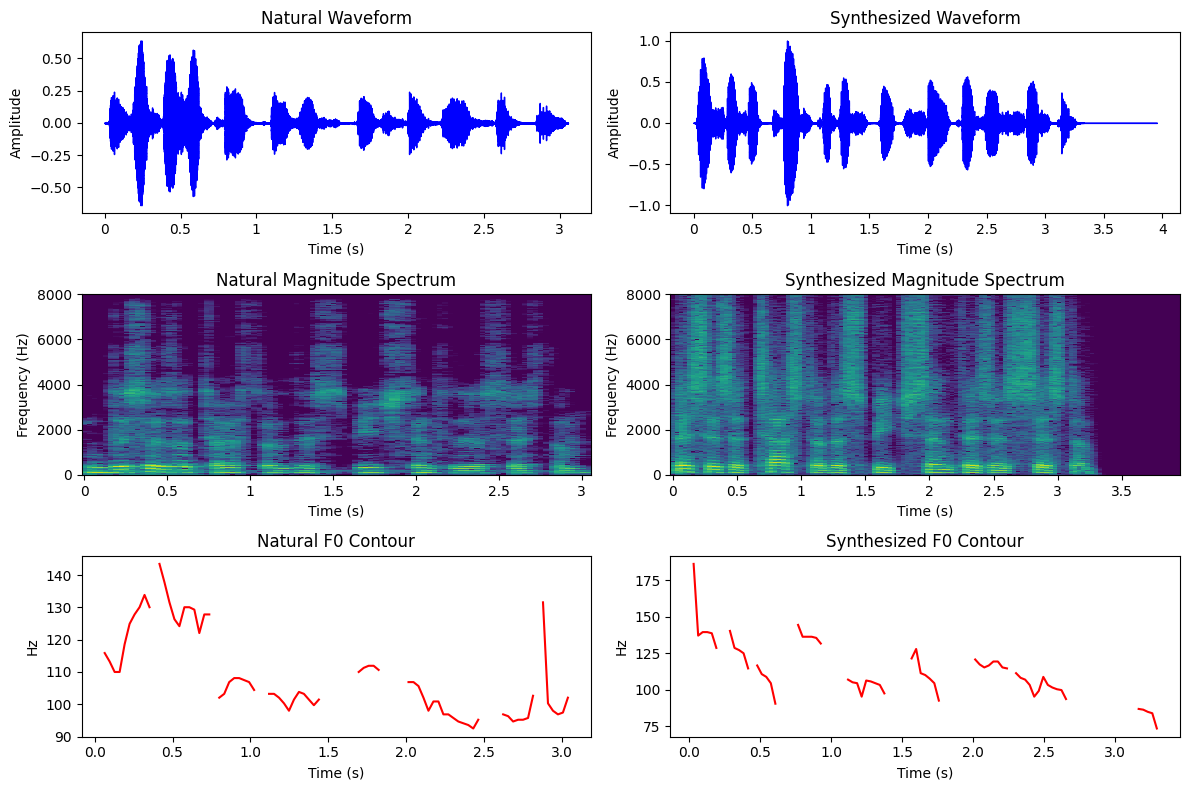

In [2]:
#Synthesizing English
ref_path = "reference_en.wav"
out_path = "output_en.wav"
text_en = "This is a test of the speech synthesis system."

tts.tts_to_file(text=text_en, speaker_wav=ref_path, language="en", file_path=out_path)

y_syn, sr_syn = librosa.load(out_path, sr=None)
y_ref, sr_ref_orig = librosa.load(ref_path, sr=None)
y_ref_plot = librosa.resample(y_ref, orig_sr=sr_ref_orig, target_sr=sr_syn)

print(f"Ref Duration: {len(y_ref)/sr_ref_orig:.2f}s | SR: {sr_ref_orig}Hz | Format: WAV")
print(f"Syn Duration: {len(y_syn)/sr_syn:.2f}s | SR: {sr_syn}Hz | Format: WAV")

def extract_f0(y, sr):
    f0, _, _ = librosa.pyin(y, fmin=librosa.note_to_hz('C2'), fmax=librosa.note_to_hz('C7'), sr=sr)
    return f0

f0_ref = extract_f0(y_ref_plot, sr_syn)
f0_syn = extract_f0(y_syn, sr_syn)

fig, axes = plt.subplots(3, 2, figsize=(12, 8))

librosa.display.waveshow(y_ref_plot, sr=sr_syn, ax=axes[0, 0], color='blue')
axes[0, 0].set_title("Natural Waveform")
axes[0, 0].set_xlabel("Time (s)")
axes[0, 0].set_ylabel("Amplitude")

librosa.display.waveshow(y_syn, sr=sr_syn, ax=axes[0, 1], color='blue')
axes[0, 1].set_title("Synthesized Waveform")
axes[0, 1].set_xlabel("Time (s)")
axes[0, 1].set_ylabel("Amplitude")

D_ref = librosa.amplitude_to_db(np.abs(librosa.stft(y_ref_plot)), ref=np.max)
D_syn = librosa.amplitude_to_db(np.abs(librosa.stft(y_syn)), ref=np.max)

librosa.display.specshow(D_ref, sr=sr_syn, x_axis='time', y_axis='linear', ax=axes[1, 0], cmap='viridis')
axes[1, 0].set_title("Natural Magnitude Spectrum")
axes[1, 0].set_xlabel("Time (s)")
axes[1, 0].set_ylabel("Frequency (Hz)")

librosa.display.specshow(D_syn, sr=sr_syn, x_axis='time', y_axis='linear', ax=axes[1, 1], cmap='viridis')
axes[1, 1].set_title("Synthesized Magnitude Spectrum")
axes[1, 1].set_xlabel("Time (s)")
axes[1, 1].set_ylabel("Frequency (Hz)")

times_ref = librosa.times_like(f0_ref, sr=sr_syn)
times_syn = librosa.times_like(f0_syn, sr=sr_syn)

axes[2, 0].plot(times_ref, f0_ref, color='r')
axes[2, 0].set_title("Natural F0 Contour")
axes[2, 0].set_xlabel("Time (s)")
axes[2, 0].set_ylabel("Hz")

axes[2, 1].plot(times_syn, f0_syn, color='r')
axes[2, 1].set_title("Synthesized F0 Contour")
axes[2, 1].set_xlabel("Time (s)")
axes[2, 1].set_ylabel("Hz")

plt.tight_layout()
plt.show()

 > Text splitted to sentences.
['Tai yra šnekos sintezės sistemos testas.']
tai yra šnekos sintezės sistemos testas.
 [!] Character 'š' not found in the vocabulary. Discarding it.
tai yra šnekos sintezės sistemos testas.
 [!] Character 'ė' not found in the vocabulary. Discarding it.
 > Processing time: 3.369478464126587
 > Real-time factor: 0.8846097306711963
Ref Duration: 2.76s | SR: 48000Hz | Format: WAV
Syn Duration: 3.81s | SR: 16000Hz | Format: WAV


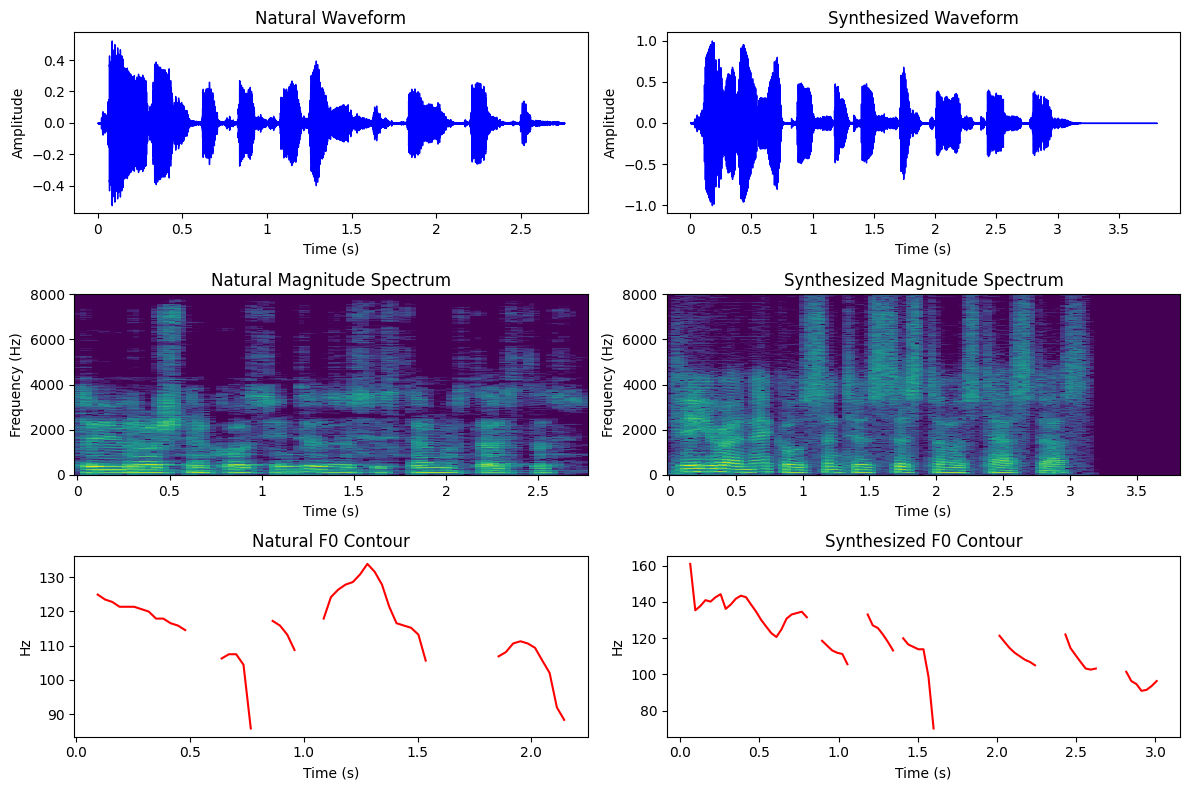

In [3]:
#Synthesizing Lithuanian
ref_path_lt = "reference_lt.wav"
out_path_lt = "output_lt.wav"
text_lt = "Tai yra šnekos sintezės sistemos testas."

tts.tts_to_file(text=text_lt, speaker_wav=ref_path_lt, language="en", file_path=out_path_lt)

y_syn_lt, sr_syn_lt = librosa.load(out_path_lt, sr=None)
y_ref_lt, sr_ref_orig_lt = librosa.load(ref_path_lt, sr=None)
y_ref_plot_lt = librosa.resample(y_ref_lt, orig_sr=sr_ref_orig_lt, target_sr=sr_syn_lt)

print(f"Ref Duration: {len(y_ref_lt)/sr_ref_orig_lt:.2f}s | SR: {sr_ref_orig_lt}Hz | Format: WAV")
print(f"Syn Duration: {len(y_syn_lt)/sr_syn_lt:.2f}s | SR: {sr_syn_lt}Hz | Format: WAV")

f0_ref_lt = extract_f0(y_ref_plot_lt, sr_syn_lt)
f0_syn_lt = extract_f0(y_syn_lt, sr_syn_lt)

fig, axes = plt.subplots(3, 2, figsize=(12, 8))

librosa.display.waveshow(y_ref_plot_lt, sr=sr_syn_lt, ax=axes[0, 0], color='blue')
axes[0, 0].set_title("Natural Waveform")
axes[0, 0].set_xlabel("Time (s)")
axes[0, 0].set_ylabel("Amplitude")

librosa.display.waveshow(y_syn_lt, sr=sr_syn_lt, ax=axes[0, 1], color='blue')
axes[0, 1].set_title("Synthesized Waveform")
axes[0, 1].set_xlabel("Time (s)")
axes[0, 1].set_ylabel("Amplitude")

D_ref_lt = librosa.amplitude_to_db(np.abs(librosa.stft(y_ref_plot_lt)), ref=np.max)
D_syn_lt = librosa.amplitude_to_db(np.abs(librosa.stft(y_syn_lt)), ref=np.max)

librosa.display.specshow(D_ref_lt, sr=sr_syn_lt, x_axis='time', y_axis='linear', ax=axes[1, 0], cmap='viridis')
axes[1, 0].set_title("Natural Magnitude Spectrum")
axes[1, 0].set_xlabel("Time (s)")
axes[1, 0].set_ylabel("Frequency (Hz)")

librosa.display.specshow(D_syn_lt, sr=sr_syn_lt, x_axis='time', y_axis='linear', ax=axes[1, 1], cmap='viridis')
axes[1, 1].set_title("Synthesized Magnitude Spectrum")
axes[1, 1].set_xlabel("Time (s)")
axes[1, 1].set_ylabel("Frequency (Hz)")

times_ref_lt = librosa.times_like(f0_ref_lt, sr=sr_syn_lt)
times_syn_lt = librosa.times_like(f0_syn_lt, sr=sr_syn_lt)

axes[2, 0].plot(times_ref_lt, f0_ref_lt, color='r')
axes[2, 0].set_title("Natural F0 Contour")
axes[2, 0].set_xlabel("Time (s)")
axes[2, 0].set_ylabel("Hz")

axes[2, 1].plot(times_syn_lt, f0_syn_lt, color='r')
axes[2, 1].set_title("Synthesized F0 Contour")
axes[2, 1].set_xlabel("Time (s)")
axes[2, 1].set_ylabel("Hz")

plt.tight_layout()
plt.show()

Total audio files found in zip009/wavs: 17096
Total metadata entries matching F3N: 32094
Total F3N audio files available in zip009: 16954
Final sampled count to process: 200

Results: 
Selected speaker: F3
Selected emotion: N
Total recordings in subset: 200
Total duration: 615.87 seconds (10.26 minutes)
Audio parameters: 96000 Hz, PCM_24, 1 channel(s)
Parameter consistency check:
Unique sample rates: [96000]
Unique bit depths: ['PCM_24']
Unique channel counts: [1]
Minimum duration: 0.81 seconds
Maximum duration: 7.86 seconds
Average duration: 3.08 seconds
Training set count (90%): 180
Validation set count (10%): 20


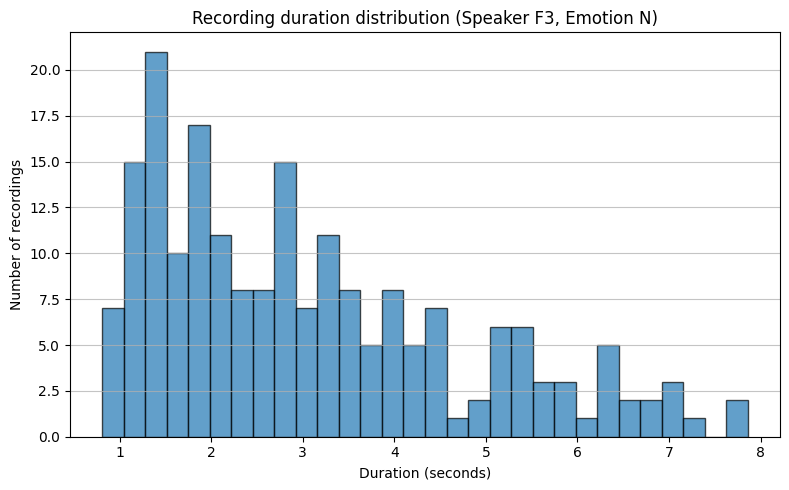

In [4]:
#Preparing the Lithuanian Dataset
metadata_path = "metadata_of_EMO_dataset.csv"
source_wavs_dir = "zip009/wavs"
output_dir = "dataset"

target_speaker = "F3"
target_emotion = "N"
MAX_SAMPLES = 200

disk_files = {}
for root, _, files in os.walk(source_wavs_dir):
    for f in files:
        if f.endswith(".wav"):
            disk_files[f] = os.path.join(root, f)

print(f"Total audio files found in zip009/wavs: {len(disk_files)}")

df = pd.read_csv(metadata_path, sep="|", encoding="utf-8", header=None)
df.columns = ["orig_path", "speaker_id", "text"]

pattern = f"{target_speaker}{target_emotion}"
filtered_df = df[df["orig_path"].str.contains(pattern, case=False, na=False)].copy()
filtered_df["filename"] = filtered_df["orig_path"].apply(lambda x: os.path.basename(str(x).strip()))
available_df = filtered_df[filtered_df["filename"].isin(disk_files)].copy()

print(f"Total metadata entries matching F3N: {len(filtered_df)}")
print(f"Total F3N audio files available in zip009: {len(available_df)}")

if len(available_df) > MAX_SAMPLES:
    available_df = available_df.sample(n=MAX_SAMPLES, random_state=123).reset_index(drop=True)

print(f"Final sampled count to process: {len(available_df)}")

target_wavs_dir = os.path.join(output_dir, "wavs")
os.makedirs(target_wavs_dir, exist_ok=True)

processed_data = []

for idx, row in available_df.iterrows():
    filename = row["filename"]
    found_file = disk_files[filename]
    
    dest_file = os.path.join(target_wavs_dir, filename)
    shutil.copy2(found_file, dest_file)
    
    duration = librosa.get_duration(path=dest_file)
    
    info = sf.info(dest_file)
    framerate = info.samplerate
    n_channels = info.channels
    bit_depth = info.subtype
    
    processed_data.append({
        "filename": filename,
        "text": row["text"],
        "duration": duration,
        "sample_rate": framerate,
        "bit_depth": bit_depth,
        "channels": n_channels
    })

data_df = pd.DataFrame(processed_data)
data_df = data_df.sample(frac=1, random_state=123).reset_index(drop=True)

split_idx = int(len(data_df) * 0.9)
train_df = data_df.iloc[:split_idx]
val_df = data_df.iloc[split_idx:]

train_csv = train_df[["filename", "text", "text"]]
val_csv = val_df[["filename", "text", "text"]]

train_csv.to_csv(os.path.join(output_dir, "metadata_train.csv"), sep="|", index=False, header=False, encoding="utf-8")
val_csv.to_csv(os.path.join(output_dir, "metadata_val.csv"), sep="|", index=False, header=False, encoding="utf-8")

durations = data_df["duration"].values

unique_rates = data_df["sample_rate"].unique()
unique_bit_depths = data_df["bit_depth"].unique()
unique_channels = data_df["channels"].unique()

sample_rate_str = f"{unique_rates[0]} Hz" if len(unique_rates) == 1 else f"mixed ({unique_rates})"
bit_depth_str = f"{unique_bit_depths[0]}" if len(unique_bit_depths) == 1 else f"mixed ({unique_bit_depths})"
channels_str = f"{unique_channels[0]} channel(s)" if len(unique_channels) == 1 else f"mixed ({unique_channels})"

print("\nResults: ")
print(f"Selected speaker: {target_speaker}")
print(f"Selected emotion: {target_emotion}")
print(f"Total recordings in subset: {len(data_df)}")
print(f"Total duration: {durations.sum():.2f} seconds ({durations.sum()/60:.2f} minutes)")
print(f"Audio parameters: {sample_rate_str}, {bit_depth_str}, {channels_str}")
print(f"Parameter consistency check:")
print(f"Unique sample rates: {unique_rates}")
print(f"Unique bit depths: {unique_bit_depths}")
print(f"Unique channel counts: {unique_channels}")
print(f"Minimum duration: {durations.min():.2f} seconds")
print(f"Maximum duration: {durations.max():.2f} seconds")
print(f"Average duration: {durations.mean():.2f} seconds")
print(f"Training set count (90%): {len(train_df)}")
print(f"Validation set count (10%): {len(val_df)}")

plt.figure(figsize=(8, 5))
plt.hist(durations, bins=30, edgecolor='black', alpha=0.7)
plt.title(f"Recording duration distribution (Speaker {target_speaker}, Emotion {target_emotion})")
plt.xlabel("Duration (seconds)")
plt.ylabel("Number of recordings")
plt.grid(axis='y', alpha=0.75)
plt.tight_layout()
plt.savefig("duration_histogram.png")
plt.show()

In [5]:
#Matching the LJSpeech structure
dataset_path = "dataset"
for csv_file in ["metadata_train.csv", "metadata_val.csv"]:
    csv_path = os.path.join(dataset_path, csv_file)
    if os.path.exists(csv_path):
        with open(csv_path, "r", encoding="utf-8") as f:
            lines = f.readlines()
        new_lines = []
        for line in lines:
            parts = line.strip().split("|")
            if parts:
                name = parts[0].strip()
                if name.endswith(".wav"):
                    name = name[:-4]
                text = parts[1].strip() if len(parts) > 1 else ""
                new_lines.append(f"{name}|{text}|{text}\n")
        with open(csv_path, "w", encoding="utf-8") as f:
            f.writelines(new_lines)

 > tts_models/multilingual/multi-dataset/your_tts is already downloaded.
 | > Found 180 files in C:\Users\Lenovo\Downloads\NLP_FILES\dataset
Train samples: 180 | Val samples: 20
Train audio: 8.9 min | Val audio: 1.3 min
 > Model fully restored. 
 > Setting up Audio Processor...
 | > sample_rate:16000
 | > resample:False
 | > num_mels:64
 | > log_func:np.log10
 | > min_level_db:-100
 | > frame_shift_ms:None
 | > frame_length_ms:None
 | > ref_level_db:20
 | > fft_size:512
 | > power:1.5
 | > preemphasis:0.97
 | > griffin_lim_iters:60
 | > signal_norm:False
 | > symmetric_norm:False
 | > mel_fmin:0
 | > mel_fmax:8000.0
 | > pitch_fmin:1.0
 | > pitch_fmax:640.0
 | > spec_gain:20.0
 | > stft_pad_mode:reflect
 | > max_norm:4.0
 | > clip_norm:False
 | > do_trim_silence:False
 | > trim_db:60
 | > do_sound_norm:False
 | > do_amp_to_db_linear:True
 | > do_amp_to_db_mel:True
 | > do_rms_norm:True
 | > db_level:-27.0
 | > stats_path:None
 | > base:10
 | > hop_length:160
 | > win_length:400
epochs:

 > Training Environment:
 | > Backend: Torch
 | > Mixed precision: False
 | > Precision: float32
 | > Num. of CPUs: 4
 | > Num. of Torch Threads: 2
 | > Torch seed: 54321
 | > Torch CUDNN: True
 | > Torch CUDNN deterministic: False
 | > Torch CUDNN benchmark: True
 | > Torch TF32 MatMul: False
 > Start Tensorboard: tensorboard --logdir=yourtts_lt_finetune\yourtts_lt_finetune-October-13-2026_06+11PM-0000000
 > Restoring from model_fixed.pth ...


 > `speakers.pth` is saved to yourtts_lt_finetune\yourtts_lt_finetune-October-13-2026_06+11PM-0000000\speakers.pth.
 > `speakers_file` is updated in the config.json.
 > `language_ids.json` is saved to yourtts_lt_finetune\yourtts_lt_finetune-October-13-2026_06+11PM-0000000\language_ids.json.
 > `language_ids_file` is updated in the config.json.


 > Restoring Model...
 > Partial model initialization...
 | > Layer missing in the model definition: speaker_encoder.conv1.weight
 | > Layer missing in the model definition: speaker_encoder.conv1.bias
 | > Layer missing in the model definition: speaker_encoder.bn1.weight
 | > Layer missing in the model definition: speaker_encoder.bn1.bias
 | > Layer missing in the model definition: speaker_encoder.bn1.running_mean
 | > Layer missing in the model definition: speaker_encoder.bn1.running_var
 | > Layer missing in the model definition: speaker_encoder.bn1.num_batches_tracked
 | > Layer missing in the model definition: speaker_encoder.layer1.0.conv1.weight
 | > Layer missing in the model definition: speaker_encoder.layer1.0.bn1.weight
 | > Layer missing in the model definition: speaker_encoder.layer1.0.bn1.bias
 | > Layer missing in the model definition: speaker_encoder.layer1.0.bn1.running_mean
 | > Layer missing in the model definition: speaker_encoder.layer1.0.bn1.running_var
 | > Layer 



> DataLoader initialization
| > Tokenizer:
	| > add_blank: True
	| > use_eos_bos: False
	| > use_phonemes: False
| > Number of instances : 180
 | > Preprocessing samples
 | > Max text length: 122
 | > Min text length: 11
 | > Avg text length: 39.86666666666667
 | 
 | > Max audio length: 1131880.0
 | > Min audio length: 116680.0
 | > Avg audio length: 429434.4
 | > Num. instances discarded samples: 0
 | > Batch group size: 0.


...

 | > Synthesizing test sentences.



 > EPOCH: 3/5
 --> yourtts_lt_finetune\yourtts_lt_finetune-October-13-2026_06+11PM-0000000

 > TRAINING (2026-10-13 19:06:48) 

   --> TIME: 2026-10-13 19:12:12 -- STEP: 0/3 -- GLOBAL_STEP: 10
     | > loss_disc: 2.188406229019165  (2.188406229019165)
     | > loss_disc_real_0: 0.1524273008108139  (0.1524273008108139)
     | > loss_disc_real_1: 0.19581589102745056  (0.19581589102745056)
     | > loss_disc_real_2: 0.23499645292758942  (0.23499645292758942)
     | > loss_disc_real_3: 0.19615431129932404  (0.19615431129932404)
     | > loss_disc_real_4: 0.2217922955751419  (0.2217922955751419)
     | > loss_disc_real_5: 0.2357897311449051  (0.2357897311449051)
     | > loss_0: 2.188406229019165  (2.188406229019165)
     | > grad_norm_0: tensor(26.0133)  (tensor(26.0133))
     | > loss_gen: 2.9301857948303223  (2.9301857948303223)
     | > loss_kl: 3.5250368118286133  (3.5250368118286133)
     | > loss_feat: 7.9989094734191895  (7.9989094734191895)
     | > loss_mel: 24.639005661010742  (

 | > Synthesizing test sentences.



 > EPOCH: 4/5
 --> yourtts_lt_finetune\yourtts_lt_finetune-October-13-2026_06+11PM-0000000

 > TRAINING (2026-10-13 19:25:01) 

   --> TIME: 2026-10-13 19:30:27 -- STEP: 0/3 -- GLOBAL_STEP: 13
     | > loss_disc: 2.214172601699829  (2.214172601699829)
     | > loss_disc_real_0: 0.1247464045882225  (0.1247464045882225)
     | > loss_disc_real_1: 0.19117222726345062  (0.19117222726345062)
     | > loss_disc_real_2: 0.2034245729446411  (0.2034245729446411)
     | > loss_disc_real_3: 0.19136133790016174  (0.19136133790016174)
     | > loss_disc_real_4: 0.19553038477897644  (0.19553038477897644)
     | > loss_disc_real_5: 0.20775766670703888  (0.20775766670703888)
     | > loss_0: 2.214172601699829  (2.214172601699829)
     | > grad_norm_0: tensor(10.4511)  (tensor(10.4511))
     | > loss_gen: 2.8271260261535645  (2.8271260261535645)
     | > loss_kl: 3.5237841606140137  (3.5237841606140137)
     | > loss_feat: 7.92569637298584  (7.92569637298584)
     | > loss_mel: 24.330928802490234  (24

 | > Synthesizing test sentences.
Total training time: 91.2 min (1.52 h)


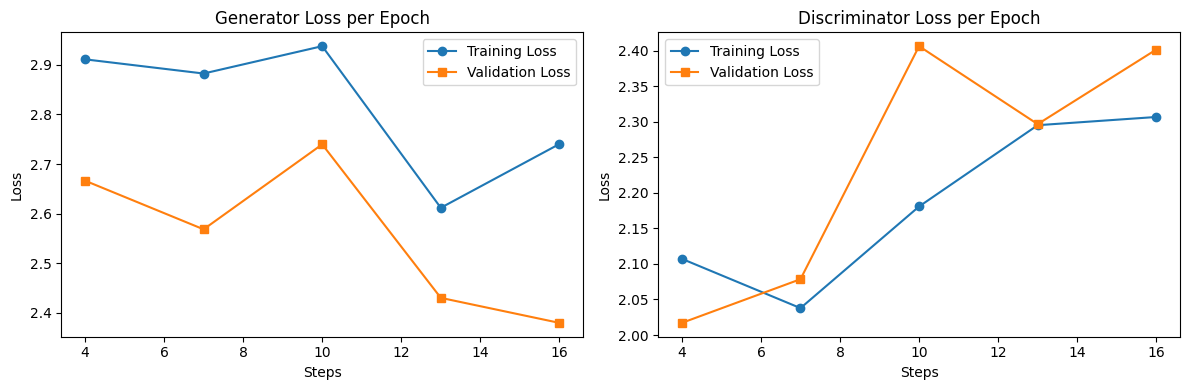

Kept: ['best_model.pth', 'config.json', 'events.out.tfevents.1791904300.DESKTOP-NEC6URI.6736.0', 'language_ids.json', 'speakers.pth', 'trainer_0_log.txt']


In [6]:
#Fine-tuning YourTTS model
import json, unicodedata
from functools import lru_cache
import torchaudio
from TTS.utils.manage import ModelManager
from TTS.config.shared_configs import BaseDatasetConfig
from TTS.tts.datasets import load_tts_samples
from TTS.tts.utils.speakers import SpeakerManager
from TTS.tts.configs.vits_config import VitsConfig
from TTS.tts.models.vits import Vits
from trainer import Trainer, TrainerArgs
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator

@lru_cache(maxsize=None)
def load16k(p):
    return librosa.load(p, sr=16000, mono=True)[0]
torchaudio.load = lambda p, *a, **k: (torch.from_numpy(load16k(str(p)).copy()).unsqueeze(0), 16000)

EPOCHS, BATCH, LR = 5, 64, 1e-4
device = "cuda" if torch.cuda.is_available() else "cpu"
model_file, config_file, _ = ModelManager().download_model("tts_models/multilingual/multi-dataset/your_tts")
md = os.path.dirname(model_file)
SE_MODEL, SE_CONFIG, LANG_IDS = [os.path.join(md, f) for f in ("model_se.pth", "config_se.json", "language_ids.json")]
DATASET_PATH, OUTPUT_PATH = "dataset", "yourtts_lt_finetune"
D_VEC = os.path.join(OUTPUT_PATH, "d_vectors.json")
FIXED = os.path.join(OUTPUT_PATH, "model_fixed.pth")
os.makedirs(OUTPUT_PATH, exist_ok=True)

ck = torch.load(model_file, map_location="cpu", weights_only=False)
ck["model"] = {(k[:-9] + ".parametrizations.weight.original0" if k.endswith(".weight_g") else k[:-9] + ".parametrizations.weight.original1" if k.endswith(".weight_v") else k): v for k, v in ck["model"].items()}
torch.save(ck, FIXED)
del ck

dataset_config = BaseDatasetConfig(formatter="ljspeech", dataset_name="lt_emo", path=DATASET_PATH,
                                   meta_file_train="metadata_train.csv", meta_file_val="metadata_val.csv", language="en")
train_samples, eval_samples = load_tts_samples(dataset_config, eval_split=True)
print("Train samples:", len(train_samples), "| Val samples:", len(eval_samples))
print(f"Train audio: {sum(sf.info(s['audio_file']).duration for s in train_samples)/60:.1f} min | Val audio: {sum(sf.info(s['audio_file']).duration for s in eval_samples)/60:.1f} min")

config = VitsConfig()
config.load_json(config_file)
vocab = set(config.characters.characters + config.characters.punctuations)
fix = lambda t: "".join(c if (c in vocab or not c.isalpha()) else unicodedata.normalize("NFD", c)[0] for c in t.lower())
for s in train_samples + eval_samples:
    s["text"] = fix(s["text"])

sm = SpeakerManager(encoder_model_path=SE_MODEL, encoder_config_path=SE_CONFIG, use_cuda=(device == "cuda"))
d_vectors = {s["audio_unique_name"]: {"name": s["speaker_name"], "embedding": np.asarray(sm.compute_embedding_from_clip(s["audio_file"])).flatten().tolist()}
             for s in train_samples + eval_samples}
json.dump(d_vectors, open(D_VEC, "w"))

config.datasets = [dataset_config]
config.output_path, config.run_name = OUTPUT_PATH, "yourtts_lt_finetune"
config.language_ids_file = config.model_args.language_ids_file = LANG_IDS
config.model_args.use_d_vector_file = True
config.d_vector_file = config.model_args.d_vector_file = [D_VEC]
config.speakers_file = config.model_args.speakers_file = None
config.model_args.speaker_encoder_model_path, config.model_args.speaker_encoder_config_path = SE_MODEL, SE_CONFIG
config.model_args.use_speaker_encoder_as_loss = False
config.use_speaker_embedding = config.use_weighted_sampler = config.use_language_weighted_sampler = False
config.epochs, config.batch_size, config.eval_batch_size = EPOCHS, BATCH, 4
config.lr_gen = config.lr_disc = LR
config.num_loader_workers = config.num_eval_loader_workers = 0
config.mixed_precision, config.run_eval, config.batch_group_size = False, True, 0
config.test_sentences = []
config.print_step, config.plot_step = 1, 1
config.save_step, config.save_n_checkpoints, config.save_best_after, config.save_all_best = 10**9, 1, 0, False
print("epochs:", config.epochs, "| batch:", config.batch_size, "| lr_gen:", config.lr_gen, "| lr_disc:", config.lr_disc)

model = Vits.init_from_config(config)
trainer = Trainer(TrainerArgs(restore_path=FIXED), config, output_path=OUTPUT_PATH, model=model,
                  train_samples=train_samples, eval_samples=eval_samples)
t0 = time.time()
trainer.fit()
train_seconds = time.time() - t0
print(f"Total training time: {train_seconds/60:.1f} min ({train_seconds/3600:.2f} h)")

run_dir = trainer.output_path
ea = EventAccumulator(run_dir, size_guidance={"scalars": 0})
ea.Reload()
tags = ea.Tags()["scalars"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, k, title in zip(axes, ["gen", "disc"], ["Generator", "Discriminator"]):
    for prefix, label, m in [("TrainEpochStats", "Training Loss", "o"), ("EvalStats", "Validation Loss", "s")]:
        t = f"{prefix}/avg_loss_{k}"
        if t in tags:
            ev = ea.Scalars(t)
            ax.plot([e.step for e in ev], [e.value for e in ev], label=label, marker=m)
    ax.set_title(f"{title} Loss per Epoch"); ax.set_xlabel("Steps"); ax.set_ylabel("Loss"); ax.legend()
plt.tight_layout(); plt.savefig("loss_curves_epochs.png", dpi=150); plt.show()

keep = {"best_model.pth", "config.json", "speakers.pth", "language_ids.json"}
for f in os.listdir(run_dir):
    p = os.path.join(run_dir, f)
    if os.path.isfile(p) and f not in keep and not f.startswith("events.out") and not f.endswith(".txt"):
        os.remove(p)
os.remove(FIXED)
print("Kept:", os.listdir(run_dir))

 > Using model: vits
 > Setting up Audio Processor...
 | > sample_rate:16000
 | > resample:False
 | > num_mels:80
 | > log_func:np.log10
 | > min_level_db:0
 | > frame_shift_ms:None
 | > frame_length_ms:None
 | > ref_level_db:None
 | > fft_size:1024
 | > power:None
 | > preemphasis:0.0
 | > griffin_lim_iters:None
 | > signal_norm:None
 | > symmetric_norm:None
 | > mel_fmin:0
 | > mel_fmax:None
 | > pitch_fmin:None
 | > pitch_fmax:None
 | > spec_gain:20.0
 | > stft_pad_mode:reflect
 | > max_norm:1.0
 | > clip_norm:True
 | > do_trim_silence:False
 | > trim_db:60
 | > do_sound_norm:False
 | > do_amp_to_db_linear:True
 | > do_amp_to_db_mel:True
 | > do_rms_norm:False
 | > db_level:None
 | > stats_path:None
 | > base:10
 | > hop_length:256
 | > win_length:1024
 > Model fully restored. 
 > Setting up Audio Processor...
 | > sample_rate:16000
 | > resample:False
 | > num_mels:64
 | > log_func:np.log10
 | > min_level_db:-100
 | > frame_shift_ms:None
 | > frame_length_ms:None
 | > ref_level_db:

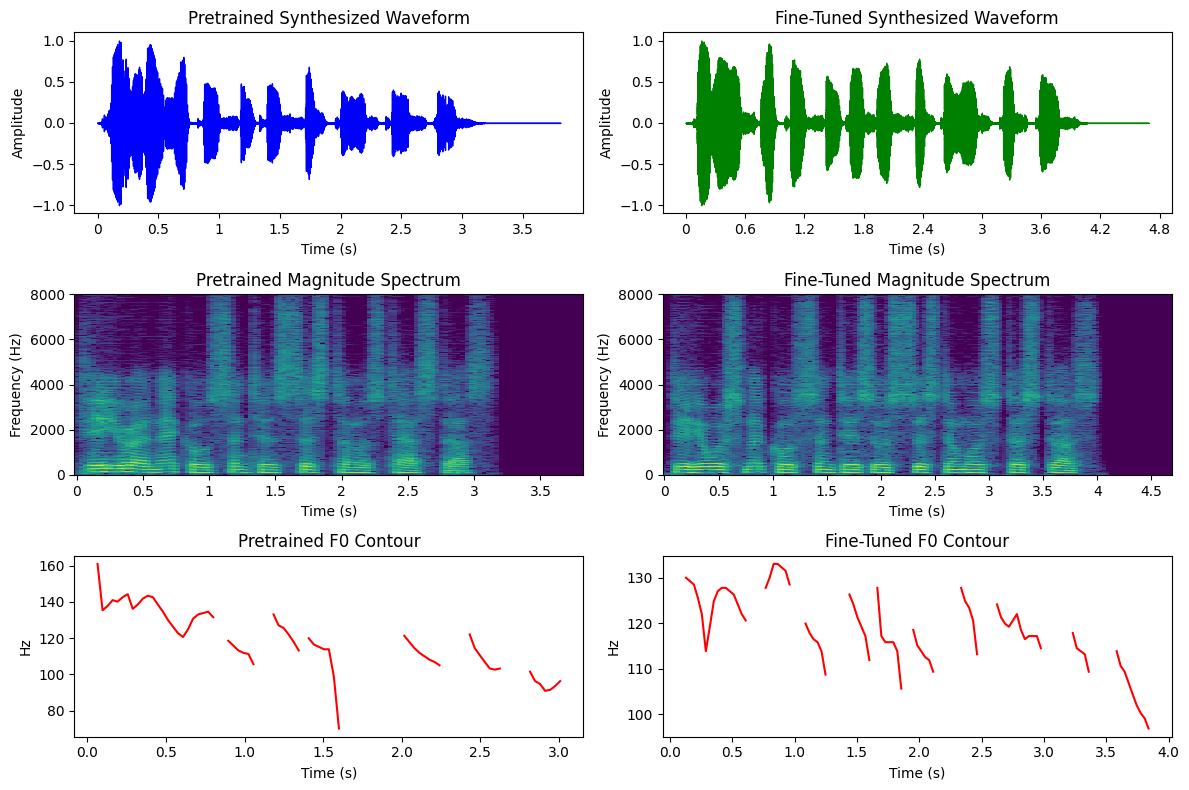

In [7]:
#Comparing the Pre-trained Model and the Fine-tuned Model
from TTS.utils.synthesizer import Synthesizer

run_dir = max(glob.glob("yourtts_lt_finetune/yourtts_lt_finetune-*"), key=os.path.getmtime)
synthesizer = Synthesizer(tts_checkpoint=os.path.join(run_dir, "best_model.pth"),
                          tts_config_path=os.path.join(run_dir, "config.json"),
                          use_cuda=torch.cuda.is_available())

ch = synthesizer.tts_config.characters
vocab = set(ch.characters + ch.punctuations)
fix = lambda t: "".join(c if (c in vocab or not c.isalpha()) else unicodedata.normalize("NFD", c)[0] for c in t.lower())

ref_path_lt = "reference_lt.wav"
out_path_ft = "output_lt_ft.wav"
out_path_orig = "output_lt.wav"
text_lt = "Tai yra šnekos sintezės sistemos testas."

wavs = synthesizer.tts(text=fix(text_lt), speaker_wav=ref_path_lt, language_name="en")
synthesizer.save_wav(wavs, out_path_ft)

y_syn_orig, sr_syn_orig = librosa.load(out_path_orig, sr=None)
y_syn_ft, sr_syn_ft = librosa.load(out_path_ft, sr=None)
print(f"Pretrained Syn Duration: {len(y_syn_orig)/sr_syn_orig:.2f}s | SR: {sr_syn_orig}Hz")
print(f"Fine-Tuned Syn Duration: {len(y_syn_ft)/sr_syn_ft:.2f}s | SR: {sr_syn_ft}Hz")

f0_syn_orig = extract_f0(y_syn_orig, sr_syn_orig)
f0_syn_ft = extract_f0(y_syn_ft, sr_syn_ft)

fig, axes = plt.subplots(3, 2, figsize=(12, 8))
for col, (y, sr, f0, name, color) in enumerate([
        (y_syn_orig, sr_syn_orig, f0_syn_orig, "Pretrained", "blue"),
        (y_syn_ft, sr_syn_ft, f0_syn_ft, "Fine-Tuned", "green")]):
    librosa.display.waveshow(y, sr=sr, ax=axes[0, col], color=color)
    axes[0, col].set_title(f"{name} Synthesized Waveform")
    axes[0, col].set_xlabel("Time (s)"); axes[0, col].set_ylabel("Amplitude")

    D = librosa.amplitude_to_db(np.abs(librosa.stft(y)), ref=np.max)
    librosa.display.specshow(D, sr=sr, x_axis="time", y_axis="linear", ax=axes[1, col], cmap="viridis")
    axes[1, col].set_title(f"{name} Magnitude Spectrum")
    axes[1, col].set_xlabel("Time (s)"); axes[1, col].set_ylabel("Frequency (Hz)")

    axes[2, col].plot(librosa.times_like(f0, sr=sr), f0, color="r")
    axes[2, col].set_title(f"{name} F0 Contour")
    axes[2, col].set_xlabel("Time (s)"); axes[2, col].set_ylabel("Hz")
plt.tight_layout()
plt.savefig("synthesis_comparison.png", dpi=150)
plt.show()